
# 🔄 Transfer Learning in Deep Learning (CNN)

---

## 1. Executive Summary

**Transfer Learning** is a powerful machine learning paradigm where knowledge (pre-trained weights and learned visual representations) gained from solving one task on a large benchmark dataset (e.g., ImageNet) is repurposed and applied to a different, but related, target task.

As prominent AI researchers like Andrew Ng have noted, Transfer Learning has become a primary driver of industrial deep learning applications because it solves two critical bottlenecks:

1. **Data Scarcity:** Eliminates the need for massive labeled custom datasets.
2. **Computational Constraints:** Reduces training time from days to minutes by reusing existing low-level feature extractors instead of training networks from scratch.

---

## 2. Core Architecture: Convolution Base vs. Classifier

A standard Convolutional Neural Network (CNN) consists of two main functional blocks:

### CNN Architecture

```text
Input Image
     |
     ▼
[ Convolutional Base (Feature Extractor) ]
     |
     ▼
[ Dense Head (Classifier) ]
     |
     ▼
Output

Convolutional Base:
├── Conv2D + Activation
└── MaxPooling

Dense Classifier Head:
├── Flatten / Pooling
├── Dense (Fully Connected)
└── Softmax / Sigmoid
````

- Convolutional Base: The series of Conv2D and Pooling layers. Responsible for extracting spatial features (edges, textures, shapes). Early layers learn generic features (edges/lines), while deeper layers capture complex, domain-specific shapes.
- Dense Classifier Head: The fully connected layers placed on top of the convolutional base. Responsible for mapping extracted spatial features to final class probability predictions.

## 3. Two Primary Strategies of Transfer Learning

Depending on the size of your target dataset and its similarity to the source dataset (ImageNet), Transfer Learning is implemented using two strategies:

### Strategy Selection Flowchart

```
                 Which Strategy to Use?
                          |
             ┌────────────┴────────────┐
             ▼                         ▼
 High Dataset Similarity       Low Dataset Similarity
        / Small Data               / Larger Data
             |                         |
             ▼                         ▼
 Feature Extraction              Fine-Tuning
             |                         |
             ▼                         ▼
 Freeze Entire Conv Base       Freeze Early Conv Layers
             |                         |
             ▼                         ▼
 Train Dense Head Only         Unfreeze Deep Conv Layers
                                      +
                               Train Dense Head
```

### Strategy A: Feature Extraction

- Mechanism: The entire convolutional base of the pre-trained model (e.g., VGG16) is frozen (`conv_base.trainable = False`). Only the newly attached Dense classification head is trained on the target dataset.
- When to Use: Ideal when the custom target dataset is small and visually similar to ImageNet categories (e.g., Cats vs. Dogs).
- Advantage: Fast training with zero risk of destroying pre-trained weights.

### Strategy B: Fine-Tuning

- Mechanism: The early convolutional layers remain frozen, while the deeper convolutional layers (e.g., `block5_conv1` onward in VGG16) are unfrozen (`trainable = True`) alongside the Dense head. The entire unblocked pipeline is trained at a very low learning rate (e.g., `1e-5` or RMSprop).
- When to Use: Ideal when the target dataset is large or significantly different from ImageNet categories (e.g., medical X-rays or specialized industrial components).
- Advantage: Adapts high-level feature detectors specifically to the target domain, yielding higher accuracy.

## 4. Performance Comparison Summary (Cat vs. Dog Benchmark)

| Approach                   | Training Setup                                    | Typical Validation Accuracy | Key Observations                                                                         |
| -------------------------- | ------------------------------------------------- | --------------------------- | ---------------------------------------------------------------------------------------- |
| Custom CNN from Scratch    | 3 Conv Layers built from scratch                  | $\approx 81%$               | Slow convergence; prone to severe overfitting without heavy regularization.              |
| Feature Extraction (VGG16) | Frozen VGG16 Conv Base + New Dense Head           | $\approx 90 - 91.4%$        | Fast convergence; stable performance; accuracy increases further with Data Augmentation. |
| Fine-Tuning (VGG16)        | Frozen Blocks 1-4 + Unfrozen Block 5 & Dense Head | $\approx 95.2%$             | Highest performance; fine-tunes deep feature detectors specifically for the target task. |

```
```

In [1]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Flatten
from keras.applications.vgg16 import VGG16

I0000 00:00:1794064083.028943    3550 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794064083.192650    3550 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794064084.817974    3550 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
conv_base = VGG16(
    weights='imagenet',
    include_top = False,
    input_shape=(150,150,3)
) 

I0000 00:00:1794064090.878840    3550 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


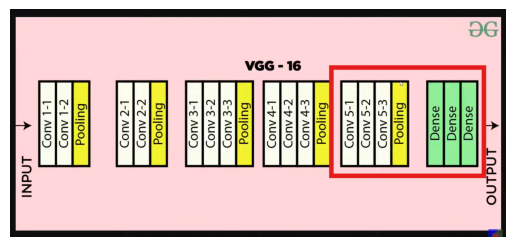

In [19]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open('Fine tuning Diagram.png')

plt.imshow(img)
plt.axis('off')
plt.show()

In [4]:
conv_base.trainable = True

set_trainable = False 

for layer in conv_base.layers:
  if layer.name == 'block5_conv1':
    set_trainable = True
  if set_trainable:
    layer.trainable = True
  else:
    layer.trainable = False

for layer in conv_base.layers:
  print(layer.name,layer.trainable) 

'''
Means , VGG had 5 conv blocks ,in feature extraction we used to use the VGG model from the Flatten layer , 
but in Fine tuning we update the last conv block(5th) too in our model
'''

input_layer False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool True


'\nMeans , VGG had 5 conv blocks ,in feature extraction we used to use the VGG model from the Flatten layer , \nbut in Fine tuning we update the last conv block(5th) too in our model\n'

In [5]:
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 7,079,424 (27.01 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [8]:
model = Sequential([
    conv_base,
    Flatten(),
    Dense(256,activation='relu'),
    Dense(1,activation='sigmoid')
])

In [9]:
# generators
train_ds = keras.utils.image_dataset_from_directory(
    directory = 'train',
    labels='inferred',
    label_mode = 'int',
    batch_size=32,
    image_size=(150,150)
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory = 'test',
    labels='inferred',
    label_mode = 'int',
    batch_size=32,
    image_size=(150,150)
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [10]:
# Normalize
def process(image,label):
    image = tensorflow.cast(image/255. ,tensorflow.float32)
    return image,label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

In [12]:
model.compile(
    optimizer=keras.optimizers.RMSprop(1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
  )

# IMP = we use RSMprop as optimerser rather then adam while fine tuning 

In [13]:
history = model.fit(train_ds,
                    epochs=10,
                    validation_data=validation_ds)

Epoch 1/10


/home/shubham/dl-gpu/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794064477.679268    3681 service.cc:153] XLA service 0x7b43f0049a60 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794064477.679305    3681 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.5.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.0)
I0000 00:00:1794064477.712685    3681 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794064478.087227    3681 cuda_dnn.cc:461] Loaded cuDNN version 92800
I0000 00:00:1794064478.119491    3681 dot_merger.cc:481]

625/625 ━━━━━━━━━━━━━━━━━━━━ 67s 74ms/step - accuracy: 0.9001 - loss: 0.2374 - val_accuracy: 0.9392 - val_loss: 0.1565
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 43s 68ms/step - accuracy: 0.9470 - loss: 0.1338 - val_accuracy: 0.9482 - val_loss: 0.1380
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 43s 68ms/step - accuracy: 0.9652 - loss: 0.0948 - val_accuracy: 0.9506 - val_loss: 0.1278
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 43s 69ms/step - accuracy: 0.9763 - loss: 0.0668 - val_accuracy: 0.9502 - val_loss: 0.1298
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 43s 68ms/step - accuracy: 0.9860 - loss: 0.0461 - val_accuracy: 0.9386 - val_loss: 0.1701
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 43s 68ms/step - accuracy: 0.9912 - loss: 0.0301 - val_accuracy: 0.9526 - val_loss: 0.1380
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 44s 71ms/step - accuracy: 0.9952 - loss: 0.0197 - val_accuracy: 0.9554 - val_loss: 0.1457
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 44s 71ms/step - accuracy: 0.9973 - loss: 0.0128 - val_accurac

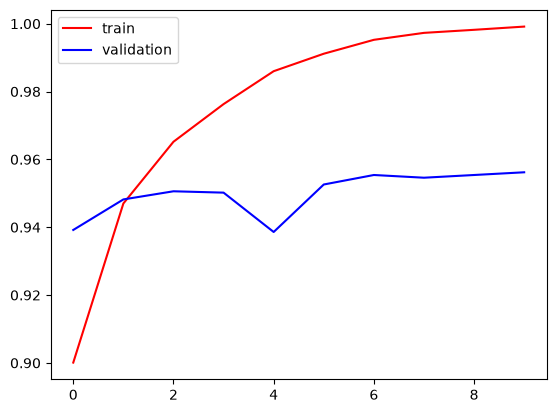

In [14]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

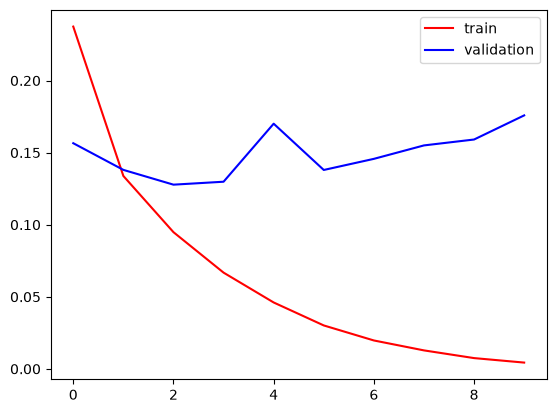

In [15]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()